# Ghost-Driver: metric depth, scale-consistent visual odometry, ISP ablation, BEV map
Monocular dashcam video in, metric 3D map + bird's-eye occupancy + measured ISP evidence out.

**Pipeline**
1. Frames -> (optional synthetic degradation) -> adaptive ISP
2. Depth-Anything-V2 **metric** outdoor depth (metres)
3. Visual odometry: LK flow + essential matrix + RANSAC, **per-frame metric scale from triangulation vs. metric depth**, yaw-only planar constraint, static-frame detection, robust step smoothing
4. Back-projection -> voxel map -> BEV (ground + obstacles + trajectory)
5. **ISP ablation** under synthetic night/rain: features, inliers, depth AbsRel, trajectory ATE
6. Export for **RTAB-Map / ROS2** (RGB, 16-bit depth in mm, camera intrinsics, TUM-format poses)

**Run:** upload one dashcam `.mp4` as a Kaggle dataset, enable GPU, run top to bottom. Outputs land in `/kaggle/working`.

In [1]:
import os, glob, json, time, shutil
import cv2, numpy as np, pandas as pd, torch
import matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import median_filter
from scipy.spatial.transform import Rotation
from transformers import pipeline

VIDEO  = sorted(glob.glob('/kaggle/input/**/*.mp4', recursive=True))[0]
OUT    = '/kaggle/working'
EXPORT = f'{OUT}/rtabmap_export'
os.makedirs(f'{EXPORT}/rgb', exist_ok=True); os.makedirs(f'{EXPORT}/depth', exist_ok=True)

# ---- config ----
FPS_OUT, MAX_FRAMES, W = 5, 150, 640
FX_RATIO   = 0.9      # fx = FX_RATIO * W. Replace with real intrinsics if you have them
HOOD_FRAC  = 0.68     # rows below this fraction are car hood / ignored. CHECK mask_check.png
SKY_FRAC   = 0.20     # rows above this fraction are sky / ignored for VO
MODE       = 'clean'  # main run input: 'clean' | 'night' | 'rain'
DEPTH_MODEL = 'depth-anything/Depth-Anything-V2-Metric-Outdoor-Small-hf'
MAX_DEPTH  = 40.0     # metres; farther depth is treated as unreliable
ABL_FRAMES = 60       # frames used per ablation run
SEED       = 0
dev = 0 if torch.cuda.is_available() else -1
print(VIDEO, 'gpu' if dev == 0 else 'cpu')

/kaggle/input/datasets/coconotchanel/single-dashcam/13588981_3840_2160_30fps.mp4 gpu


150 frames 640 x 360 | sampled fps: 5.0


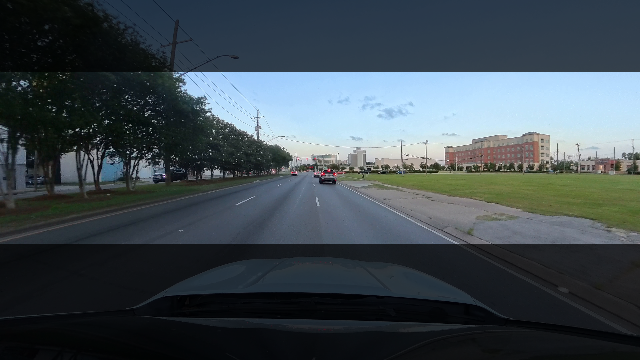

In [2]:
cap = cv2.VideoCapture(VIDEO); src = cap.get(cv2.CAP_PROP_FPS) or 30
step = max(1, int(round(src / FPS_OUT))); frames = []; i = 0
while len(frames) < MAX_FRAMES:
    ok, f = cap.read()
    if not ok: break
    if i % step == 0:
        frames.append(cv2.resize(f, (W, int(f.shape[0] * W / f.shape[1]))))
    i += 1
H = frames[0].shape[0]
FPS_EFF = src / step                      # actual sampled frame rate
fx = FX_RATIO * W; cx, cy = W / 2, H / 2
K = np.array([[fx, 0, cx], [0, fx, cy], [0, 0, 1]], dtype=np.float64)
HOOD = int(H * HOOD_FRAC)
MASK = np.zeros((H, W), np.uint8); MASK[int(H * SKY_FRAC):HOOD] = 255   # VO feature region

chk = frames[len(frames) // 2].copy()
chk[MASK == 0] = (chk[MASK == 0] * 0.3).astype(np.uint8)                # dimmed = ignored
cv2.imwrite(f'{OUT}/mask_check.png', chk)
print(len(frames), 'frames', W, 'x', H, '| sampled fps:', round(FPS_EFF, 2))
Image.fromarray(chk[..., ::-1])

In [3]:
def degrade(bgr, mode, seed=0):
    rng = np.random.default_rng(seed)
    f = bgr.astype(np.float32) / 255
    if mode == 'night':
        f = (f ** 1.8) * 0.35 + rng.normal(0, 0.03, f.shape)
    elif mode == 'rain':
        f = cv2.GaussianBlur(f, (0, 0), 1.5) * 0.7 + 0.15
        streaks = np.zeros(f.shape[:2], np.float32); h, w = streaks.shape
        for _ in range(60):
            x0, y0 = int(rng.integers(0, w)), int(rng.integers(0, h))
            cv2.line(streaks, (x0, y0), (x0 - 4, y0 + 25), 0.25, 1)
        f = f + streaks[..., None]
    return (np.clip(f, 0, 1) * 255).astype(np.uint8)

def adaptive_isp(bgr, wb=True, gamma=True, clahe=True):
    f = bgr.astype(np.float32)
    if wb: f *= f.mean() / (f.mean((0, 1)) + 1e-6)                   # gray-world white balance
    f = np.clip(f, 0, 255).astype(np.uint8)
    lab = cv2.cvtColor(f, cv2.COLOR_BGR2LAB); L = lab[..., 0]
    m = float(L.mean()) / 255
    if gamma:                                                         # scene-adaptive exposure
        g = float(np.clip(np.log(0.5) / np.log(m + 1e-3), 0.4, 2.0))
        L = cv2.LUT(L, ((np.arange(256) / 255) ** g * 255).astype(np.uint8))
    if clahe and m < 0.45:                                            # local contrast only when under-exposed
        L = cv2.createCLAHE(2.0 + 4 * (0.45 - m), (8, 8)).apply(L)
    lab[..., 0] = L
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

raw = [degrade(f, MODE, i) for i, f in enumerate(frames)]
isp = [adaptive_isp(f) for f in raw]
k = len(raw) // 2
cv2.imwrite(f'{OUT}/before_after.png', np.hstack([raw[k], isp[k]]))
print('luma before/after:', raw[k].mean().round(1), isp[k].mean().round(1))

luma before/after: 112.3 118.9


In [4]:
pipe = pipeline('depth-estimation', model=DEPTH_MODEL, device=dev)

def depth_batch(imgs, bs=8):
    rgb = [Image.fromarray(cv2.cvtColor(f, cv2.COLOR_BGR2RGB)) for f in imgs]
    outs = pipe(rgb, batch_size=bs)
    res = []
    for o, f in zip(outs, imgs):
        d = o['predicted_depth'].squeeze().float().cpu().numpy()           # metres
        d = cv2.resize(d, (f.shape[1], f.shape[0]))
        res.append(np.clip(d, 0.1, 80.0).astype(np.float32))
    return res

_ = depth_batch(isp[:2])                                                    # warm-up
if dev == 0: torch.cuda.synchronize()
t0 = time.time(); depths = depth_batch(isp)
if dev == 0: torch.cuda.synchronize()
DEPTH_MS = (time.time() - t0) / len(isp) * 1000
print('depth ms/frame:', round(DEPTH_MS, 1))

config.json:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/437 [00:00<?, ?B/s]

depth ms/frame: 31.8


In [5]:
# Visual odometry with per-frame metric scale
MIN_PARALLAX, MAX_STEP = 0.4, 6.0     # px (below = vehicle treated as stationary), metres per frame

def yaw_only(R):                       # planar-road constraint: keep rotation about the vertical (y) axis
    yaw = np.arctan2(R[0, 2], R[2, 2]); c, s = np.cos(yaw), np.sin(yaw)
    return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])

def estimate_motion(imgs, depths):
    g = [cv2.cvtColor(f, cv2.COLOR_BGR2GRAY) for f in imgs]; n = len(g) - 1
    Rs = [np.eye(3) for _ in range(n)]
    dirs = [np.array([0., 0., -1.]) for _ in range(n)]   # fallback = straight ahead (t points backwards)
    scale = np.full(n, np.nan); static = np.zeros(n, bool)
    inl_n = np.zeros(n); feat_n = np.zeros(n)
    P0 = K @ np.hstack([np.eye(3), np.zeros((3, 1))])
    for i in range(n):
        p0 = cv2.goodFeaturesToTrack(g[i], 1500, 0.01, 8, mask=MASK)
        if p0 is None: continue
        feat_n[i] = len(p0)
        p1, st, _ = cv2.calcOpticalFlowPyrLK(g[i], g[i + 1], p0, None)
        m = st.ravel() == 1; p0, p1 = p0[m], p1[m]
        if len(p0) < 30: continue
        E, inl = cv2.findEssentialMat(p0, p1, K, cv2.RANSAC, 0.999, 1.0)
        if E is None or E.shape != (3, 3): continue
        kk, R, t, inl = cv2.recoverPose(E, p0, p1, K, mask=inl.copy())
        inl_n[i] = kk
        ok = inl.ravel() > 0
        q0 = p0[ok].reshape(-1, 2).astype(np.float64); q1 = p1[ok].reshape(-1, 2).astype(np.float64)
        if len(q0) < 20: continue
        Rs[i] = yaw_only(R)
        if np.median(np.linalg.norm(q1 - q0, axis=1)) < MIN_PARALLAX:
            static[i] = True; continue
        td = t.ravel() * [1, 0, 1]; dirs[i] = td / (np.linalg.norm(td) + 1e-9)
        # metric scale: triangulated depth (unit baseline) vs. metric depth map
        X = cv2.triangulatePoints(P0, K @ np.hstack([R, t.reshape(3, 1)]), q0.T, q1.T)
        zu = X[2] / X[3]
        u = np.clip(q0[:, 0].astype(int), 0, W - 1); v = np.clip(q0[:, 1].astype(int), 0, H - 1)
        zd = depths[i][v, u]
        good = np.isfinite(zu) & (zu > 0.01) & (zd < MAX_DEPTH)
        if good.sum() >= 20: scale[i] = np.median(zd[good] / zu[good])
    return dict(R=Rs, dir=dirs, scale=scale, static=static, inliers=inl_n, feats=feat_n)

def integrate(res):
    s = res['scale'].copy(); st = res['static']; ok = np.isfinite(s) & ~st
    if ok.sum() == 0: s[:] = 0
    else:
        idx = np.arange(len(s)); s[~ok] = np.interp(idx[~ok], idx[ok], s[ok])
        s = median_filter(s, 5, mode='nearest')
    s = np.clip(s, 0, MAX_STEP); s[st] = 0
    poses = [np.eye(4)]
    for R, d, kk in zip(res['R'], res['dir'], s):
        T = np.eye(4); T[:3, :3] = R; T[:3, 3] = d * kk           # frame a -> frame b
        poses.append(poses[-1] @ np.linalg.inv(T))
    return np.array(poses), s

res = estimate_motion(isp, depths)
poses, steps = integrate(res)
path = poses[:, :3, 3]
PATH_LEN = float(np.linalg.norm(np.diff(path, axis=0), axis=1).sum())
MED_STEP = float(np.median(steps[steps > 0])) if (steps > 0).any() else 0.0
print(f'median step {MED_STEP:.2f} m | implied speed {MED_STEP * FPS_EFF:.1f} m/s = {MED_STEP * FPS_EFF * 3.6:.0f} km/h | path {PATH_LEN:.1f} m | static frames {int(res["static"].sum())}')
print('SANITY: implied speed should match the real car speed. If not, intrinsics (FX_RATIO) or depth scale are off.')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(path[:, 0], path[:, 2], '-o', ms=2); ax[0].set_aspect('equal'); ax[0].set_title('VO trajectory (m)'); ax[0].set_xlabel('x'); ax[0].set_ylabel('z')
ax[1].plot(steps); ax[1].set_title('metric step per frame (m)'); ax[1].set_xlabel('frame')
plt.tight_layout(); plt.savefig(f'{OUT}/trajectory.png', dpi=130); plt.show()

median step 2.93 m | implied speed 14.6 m/s = 53 km/h | path 386.7 m | static frames 3
SANITY: implied speed should match the real car speed. If not, intrinsics (FX_RATIO) or depth scale are off.


186126 points after voxel filter
estimated camera height above ground: 2.19 m (dashcam is typically 1.1-1.6 m)


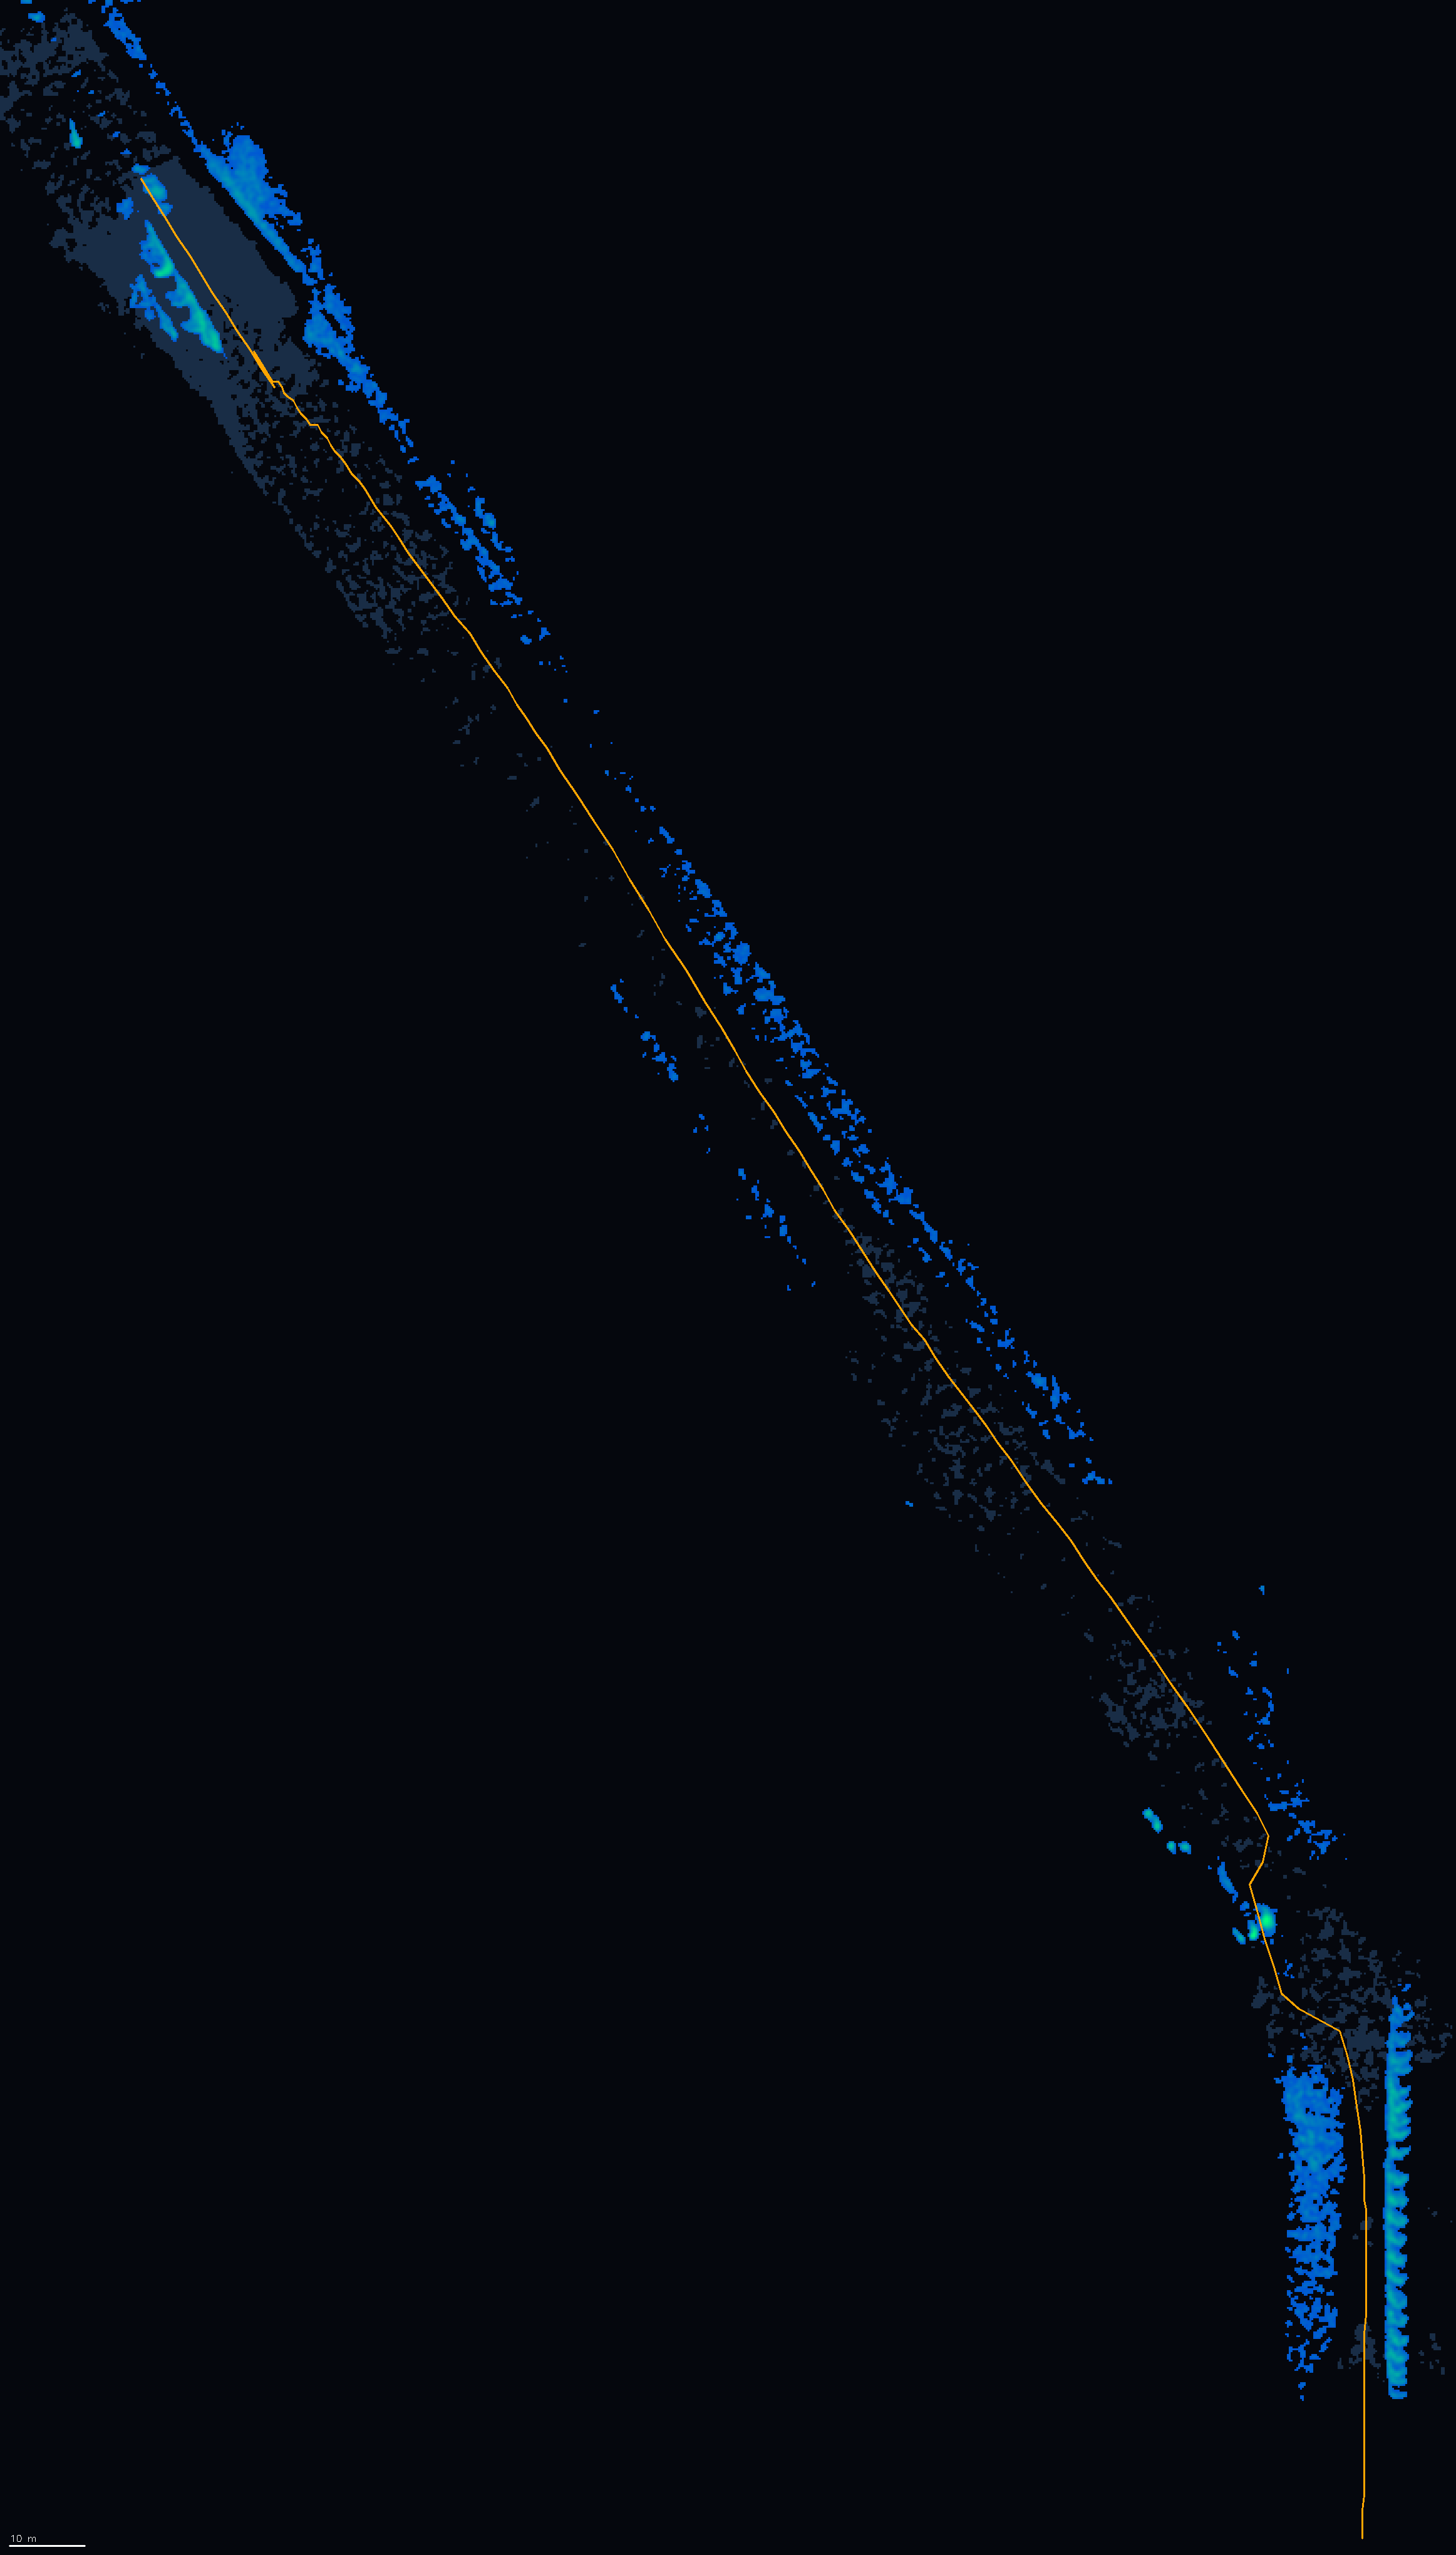

In [6]:
# Back-project into the world frame (metric), voxel-downsample, build BEV
def backproject(imgs, depths, poses, n=6000, seed=SEED):
    rng = np.random.default_rng(seed); pts, cols = [], []
    for f, d, T in zip(imgs, depths, poses):
        u = rng.integers(0, W, n); v = rng.integers(int(H * 0.35), HOOD, n)
        z = d[v, u]; m = z < 30
        u, v, z = u[m], v[m], z[m]
        x = (u - cx) * z / fx; y = (v - cy) * z / fx
        P = np.stack([x, y, z, np.ones_like(z)], -1) @ T.T
        pts.append(P[:, :3]); cols.append(f[v, u][:, ::-1])
    pts = np.concatenate(pts); cols = np.concatenate(cols)
    _, idx = np.unique(np.floor(pts / 0.15).astype(np.int32), axis=0, return_index=True)
    return pts[idx], cols[idx]

pts, cols = backproject(isp, depths, poses)
print(len(pts), 'points after voxel filter')

def render_bev(pts, path, res_m=0.25, scale=3):
    gy = np.percentile(pts[:, 1], 90)                                 # camera y points down -> ground = large y
    print('estimated camera height above ground: %.2f m (dashcam is typically 1.1-1.6 m)' % gy)
    obs = (pts[:, 1] < gy - 0.3) & (pts[:, 1] > gy - 3.0)
    gnd = np.abs(pts[:, 1] - gy) < 0.2
    keep = obs | gnd
    x, z = pts[keep, 0], pts[keep, 2]
    x0, x1 = np.percentile(x, [0.5, 99.5]); z0, z1 = np.percentile(z, [0.5, 99.5])
    x0, x1 = min(x0, path[:, 0].min() - 5), max(x1, path[:, 0].max() + 5)
    z0, z1 = min(z0, path[:, 2].min() - 2), max(z1, path[:, 2].max() + 2)
    Wb, Hb = int((x1 - x0) / res_m) + 1, int((z1 - z0) / res_m) + 1
    def to_px(px, pz): return ((px - x0) / res_m).astype(int), ((z1 - pz) / res_m).astype(int)   # forward = up
    def grid(mask):
        gx, gz = to_px(pts[mask, 0], pts[mask, 2]); ok = (gx >= 0) & (gx < Wb) & (gz >= 0) & (gz < Hb)
        G = np.zeros((Hb, Wb), np.float32); np.add.at(G, (gz[ok], gx[ok]), 1); return cv2.GaussianBlur(G, (0, 0), 1.0)
    G_o, G_g = grid(obs), grid(gnd)
    img = np.full((Hb, Wb, 3), (13, 7, 5), np.uint8)
    img[G_g >= 1.0] = (70, 45, 25)                                    # drivable surface (dim)
    o = G_o >= 1.5
    heat = cv2.applyColorMap((np.log1p(G_o) / np.log1p(G_o.max()) * 255).astype(np.uint8), cv2.COLORMAP_WINTER)
    img[o] = heat[o]                                                  # obstacles (bright)
    img = cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_NEAREST)
    px, pz = to_px(path[:, 0], path[:, 2])
    cv2.polylines(img, [np.stack([px, pz], 1).reshape(-1, 1, 2) * scale], False, (0, 165, 255), 2)
    bar = int(10 / res_m * scale); cv2.line(img, (15, img.shape[0] - 15), (15 + bar, img.shape[0] - 15), (255, 255, 255), 2)
    cv2.putText(img, '10 m', (15, img.shape[0] - 22), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)
    return img

bev = render_bev(pts, path)
cv2.imwrite(f'{OUT}/bev.png', bev)
Image.fromarray(bev[..., ::-1])

In [7]:
# ISP ablation: raw vs WB+gamma vs full ISP under synthetic night / rain.
# Reference = pipeline output on the CLEAN frames (NOT ground truth).
def align_rigid(ref, est):             # 2D rigid alignment (no scale, trajectories are metric)
    mr, me = ref.mean(0), est.mean(0)
    U, S, Vt = np.linalg.svd((est - me).T @ (ref - mr))
    D = np.diag([1, np.sign(np.linalg.det(Vt.T @ U.T))])
    R = Vt.T @ D @ U.T
    return est @ R.T + (mr - R @ me)

ROWS = slice(int(H * .35), HOOD)
def absrel(ref, tst):
    r, t = ref[ROWS], tst[ROWS]; v = r < MAX_DEPTH
    return float(np.mean(np.abs(t[v] - r[v]) / r[v]))

def evaluate(imgs):
    d = depth_batch(imgs); r = estimate_motion(imgs, d); p, s = integrate(r)
    return d, p[:, :3, 3][:, [0, 2]], dict(features=r['feats'].mean(), inliers=r['inliers'].mean())

VARIANTS = {'raw': None, 'WB+gamma': dict(clahe=False), 'full ISP': dict()}
clean = frames[::2][:ABL_FRAMES]
ref_d, ref_p, ref_m = evaluate(clean)
ref_len = np.linalg.norm(np.diff(ref_p, axis=0), axis=1).sum()
rows = [dict(degradation='clean', input='raw (reference)', features=round(ref_m['features']), inliers=round(ref_m['inliers']),
             depth_AbsRel=0.0, ATE_m=0.0, path_len_err_pct=0.0)]
gallery = []
for mode in ['clean', 'night', 'rain']:
    deg = [degrade(f, mode, i) for i, f in enumerate(clean)]
    for name, kw in VARIANTS.items():
        if mode == 'clean' and name == 'raw': continue
        imgs = deg if kw is None else [adaptive_isp(f, **kw) for f in deg]
        d, p, m = evaluate(imgs)
        ate = float(np.sqrt(np.mean(np.sum((align_rigid(ref_p, p) - ref_p) ** 2, 1))))
        plen = np.linalg.norm(np.diff(p, axis=0), axis=1).sum()
        rows.append(dict(degradation=mode, input=name, features=round(m['features']), inliers=round(m['inliers']),
                         depth_AbsRel=round(float(np.mean([absrel(a, b) for a, b in zip(ref_d, d)])), 3),
                         ATE_m=round(ate, 2), path_len_err_pct=round(100 * (plen - ref_len) / ref_len, 1)))
        if mode != 'clean' and name in ('raw', 'full ISP'): gallery.append((mode, name, imgs[len(imgs) // 2]))
df = pd.DataFrame(rows); print(df.to_string(index=False))
df.to_csv(f'{OUT}/isp_eval.csv', index=False)
try: open(f'{OUT}/isp_eval.md', 'w').write(df.to_markdown(index=False))
except Exception as e: print('markdown export skipped:', e)
cv2.imwrite(f'{OUT}/isp_gallery.png', np.vstack([np.hstack([g[2] for g in gallery[:2]]), np.hstack([g[2] for g in gallery[2:4]])]))

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


degradation           input  features  inliers  depth_AbsRel  ATE_m  path_len_err_pct
      clean raw (reference)       433      192         0.000   0.00               0.0
      clean        WB+gamma       435      195         0.017   5.48               6.5
      clean        full ISP       451      196         0.019  10.78               9.5
      night             raw       934      304         0.093  13.41             -13.8
      night        WB+gamma       870      300         0.217  16.46             -25.5
      night        full ISP      1020      323         0.292  20.76             -39.3
       rain             raw       300      119         0.057   7.33             -11.1
       rain        WB+gamma       301      116         0.054   6.09              -7.6
       rain        full ISP       305      118         0.055   7.61              -2.7


True

In [8]:
# Exports: RTAB-Map / ROS2 inputs, demo GIF, summary
for i, (f, d) in enumerate(zip(isp, depths)):
    cv2.imwrite(f'{EXPORT}/rgb/{i:06d}.png', f)
    dm = d.copy(); dm[dm > MAX_DEPTH] = 0; dm[HOOD:] = 0                  # 0 = invalid (far depth, car hood)
    cv2.imwrite(f'{EXPORT}/depth/{i:06d}.png', (dm * 1000).astype(np.uint16))   # 16UC1, millimetres
ts = np.arange(len(isp)) / FPS_EFF
open(f'{EXPORT}/rgb.txt', 'w').write('\n'.join(f'{t:.6f} rgb/{i:06d}.png' for i, t in enumerate(ts)))
open(f'{EXPORT}/depth.txt', 'w').write('\n'.join(f'{t:.6f} depth/{i:06d}.png' for i, t in enumerate(ts)))
tum = []
for t, T in zip(ts, poses):                                              # camera-to-world, optical frame (x right, y down, z fwd)
    q = Rotation.from_matrix(T[:3, :3]).as_quat()
    tum.append(f'{t:.6f} {T[0,3]:.5f} {T[1,3]:.5f} {T[2,3]:.5f} {q[0]:.6f} {q[1]:.6f} {q[2]:.6f} {q[3]:.6f}')
open(f'{EXPORT}/poses_tum.txt', 'w').write('\n'.join(tum))
json.dump(dict(width=W, height=H, fx=fx, fy=fx, cx=cx, cy=cy, depth_scale=1000, fps=FPS_EFF,
               note='fx is an assumption (FX_RATIO*W) unless replaced with real calibration'),
          open(f'{EXPORT}/camera.json', 'w'), indent=1)

# demo GIF: raw | ISP | metric depth
def tile(a, b, d):
    dc = cv2.applyColorMap((np.clip(d / MAX_DEPTH, 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_TURBO)
    t = np.hstack([a, b, dc]); return Image.fromarray(cv2.resize(t, None, fx=0.5, fy=0.5)[..., ::-1])
G = [tile(a, b, d) for a, b, d in list(zip(raw, isp, depths))[:60]]
G[0].save(f'{OUT}/demo.gif', save_all=True, append_images=G[1:], duration=200, loop=0)

# map exports
P = pts.copy(); P[:, 1] *= -1; pa = path * np.array([1, -1, 1])
P.astype('float32').tofile(f'{OUT}/points_xyz.bin'); cols.astype('uint8').tofile(f'{OUT}/points_rgb.bin')
json.dump({'n': int(len(P)), 'path': pa.tolist()}, open(f'{OUT}/meta.json', 'w'))
np.savez(f'{OUT}/scene.npz', xyz=P.astype('float32'), rgb=cols, path=pa)
json.dump(dict(mode=MODE, frames=len(isp), fps=FPS_EFF, depth_ms_per_frame=round(DEPTH_MS, 1), median_step_m=round(MED_STEP, 2),
               implied_speed_kmh=round(MED_STEP * FPS_EFF * 3.6, 1), path_length_m=round(PATH_LEN, 1), points=int(len(pts)),
               fx_assumed=fx, depth_model=DEPTH_MODEL), open(f'{OUT}/summary.json', 'w'), indent=1)
shutil.make_archive('/tmp/rtabmap_export', 'zip', EXPORT); shutil.move('/tmp/rtabmap_export.zip', f'{OUT}/rtabmap_export.zip')
print(sorted(os.listdir(OUT)))

['__notebook__.ipynb', 'before_after.png', 'bev.png', 'demo.gif', 'isp_eval.csv', 'isp_eval.md', 'isp_gallery.png', 'mask_check.png', 'meta.json', 'points_rgb.bin', 'points_xyz.bin', 'rtabmap_export', 'rtabmap_export.zip', 'scene.npz', 'summary.json', 'trajectory.png']


## Results (fill in from your run)
- Depth: `{depth ms/frame}` on `{GPU}` | median step / implied speed / path length from `summary.json`
- ISP ablation table: `isp_eval.csv`. Report it as measured, including rows where the ISP hurts (for example clean input).
- Degradation is **synthetic** and the reference is the clean-frame output, **not ground truth**. Repeat the ablation on a real night clip if you can.

## Limitations
- Intrinsics are assumed (`FX_RATIO`) unless you calibrate. Wrong `fx` biases both scale and yaw.
- Monocular VO with planar-road constraint; no loop closure, so drift accumulates. Metric scale comes from a learned depth model and can vary by scene.
- Metric depth is a prediction, not a measurement; far range (>40 m) is discarded.

## Next: RTAB-Map / ROS2
`rtabmap_export/` holds `rgb/`, `depth/` (16UC1 mm, 0 = invalid), `rgb.txt`, `depth.txt` (TUM style timestamps), `camera.json` and `poses_tum.txt` (this notebook's VO path, for comparison with RTAB-Map using `evo`). Pack into a rosbag2 with `/camera/image_raw`, `/camera/depth`, `/camera/camera_info`, then run `rtabmap_ros` and compare trajectories. A loop (drive around a block) is needed to show loop closure.